# Multi-LexSum: Legal Case Summarization

**Multi-LexSum** is a multi-document summarization dataset of civil rights legal cases with expert-authored summaries at three levels of granularity: multi-paragraph, single-page, and single-sentence. 

This notebook loads the dataset, explores key statistics, cleans the source text, generates extractive summaries at each granularity level, and evaluates T5-generated summaries against expert references using cosine similarity scores.

In [25]:
import warnings
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import nltk

from collections import Counter
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from transformers import pipeline
from tqdm import tqdm

# Enable tqdm integration with pandas
tqdm.pandas()

for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet']:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings('ignore')

## Load Data & Key Findings

In [2]:
# Load data
dataset = load_dataset('allenai/multi_lexsum', name='v20230518', trust_remote_code=True)

# Count total cases
total = sum(len(v) for v in dataset.values())

# Print cases per split
for split, data in dataset.items():
    print(f'{split}: {len(data)} cases')

# Print total cases
print(f'\nTotal: {total} cases')

train: 3177 cases
validation: 454 cases
test: 908 cases

Total: 4539 cases


In [3]:
train = dataset['train']

# Print first five rows of training data
train.to_pandas().head()

,id,sources,sources_metadata,summary/long,summary/short,summary/tiny,case_metadata
0,EE-AL-0045,[Case 1:05-cv-00530-D Document 1-1 Filed 09/19...,"{'doc_id': ['EE-AL-0045-0001', 'EE-AL-0045-000...","On September 15, 2005, the Equal Employment Op...",Equal Employment Opportunity Commission brough...,NaN,{'case_name': 'EEOC v. House of Philadelphia C...
1,PB-NJ-0003,[Case 3:05-cv-01784-SRC-JJH Document 2 Filed 0...,"{'doc_id': ['PB-NJ-0003-0001', 'PB-NJ-0003-000...",NOTE: This is one of three identically named ...,The case was brought by a non-profit organizat...,NaN,{'case_name': 'Disability Rights New Jersey v....
2,EE-FL-0136,[Case 9:07-cv-80713-KAM Document 1 Entered on ...,"{'doc_id': ['EE-FL-0136-0001', 'EE-FL-0136-000...","On August 9, 2007, the United States Departmen...",NaN,NaN,{'case_name': 'United States v. Palm Beach Cou...
3,EE-CA-0305,[2006 WL 1787244\n2006 WL 1787244 (N.D.Cal.) (...,"{'doc_id': ['EE-CA-0305-0001', 'EE-CA-0305-000...","On May 11, 2006, African-American employees of...",This case was brought by African American empl...,NaN,{'case_name': 'Wynne v. McCormick & Schmick's ...
4,NH-NJ-0002,[IN THE UNITED STATES DISTRICT COURT FOR THE D...,"{'doc_id': ['NH-NJ-0002-0001', 'NH-NJ-0002-000...",Pursuant to the Civil Rights of Institutionali...,Pursuant to the Civil Rights of Institutionali...,NaN,"{'case_name': 'U.S. v. Mercer County, New Jers..."


In [4]:
# Print % of summaries available
for level in ['long', 'short', 'tiny']:
    n = sum(1 for ex in train if ex[f'summary/{level}'])
    print(f'{level}: {n} / {len(train)} ({100*n/len(train):.1f}%)')

long: 3177 / 3177 (100.0%)
short: 2210 / 3177 (69.6%)
tiny: 1130 / 3177 (35.6%)


In [5]:
# Count characters per source document
src_chars = [sum(len(s) for s in ex['sources']) for ex in train]

# Count sources per case
n_sources = [len(ex['sources']) for ex in train]

# Print summary statistics
print(f'Mean characters: {np.mean(src_chars):.0f}')
print(f'Median characters: {np.median(src_chars):.0f}')
print(f'Maximum characters: {max(src_chars)}')
print(f'Minimum characters: {min(src_chars)}')
print(f'\nMean docs per case: {np.mean(n_sources):.1f}')
print(f'Median docs per case: {np.median(n_sources):.1f}')
print(f'Maximum docs per case: {max(n_sources)}')
print(f'Minimum docs per case: {min(n_sources)}')

Mean characters: 406421
Median characters: 160812
Maximum characters: 23501994
Minimum characters: 6052

Mean docs per case: 9.0
Median docs per case: 6.0
Maximum docs per case: 336
Minimum docs per case: 2


In [6]:
# Get length of each summary
long_lens = [len(ex['summary/long']) for ex in train if ex['summary/long']]
short_lens = [len(ex['summary/short']) for ex in train if ex['summary/short']]
tiny_lens = [len(ex['summary/tiny']) for ex in train if ex['summary/tiny']]

# Print average length by granularity
print(f'Long average: {np.mean(long_lens):.0f} characters')
print(f'Short average: {np.mean(short_lens):.0f} characters')
print(f'Tiny average: {np.mean(tiny_lens):.0f} characters')

Long average: 3588 characters
Short average: 732 characters
Tiny average: 145 characters


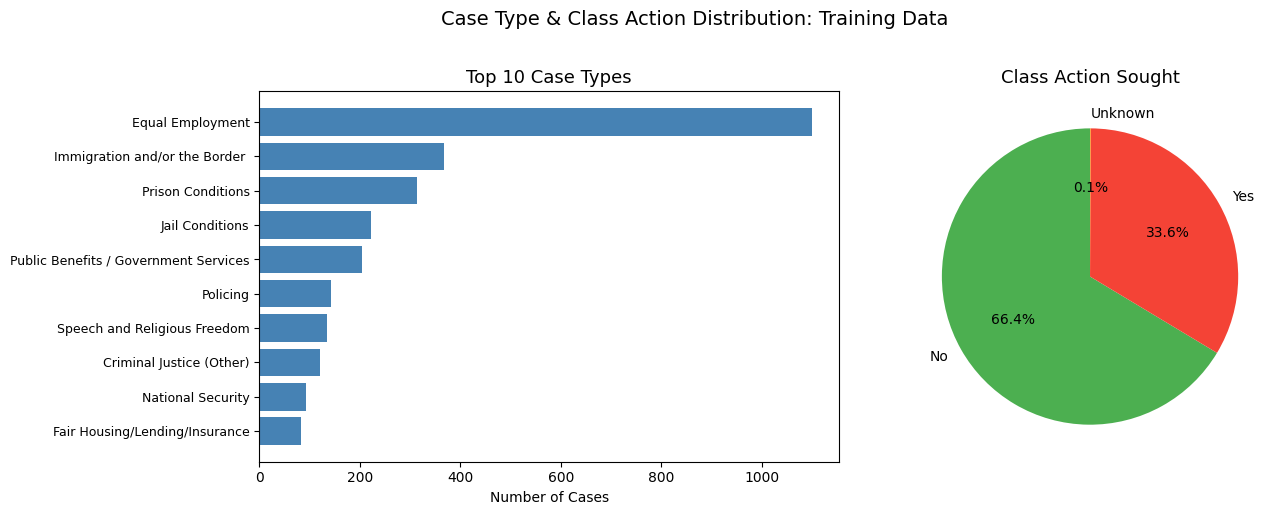

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Create bar chart of case types
case_types = [ex['case_metadata']['case_type'] for ex in train]
top_types = Counter(case_types).most_common(10)
labels, counts = zip(*top_types)
axes[0].barh(labels[::-1], counts[::-1], color='steelblue')
axes[0].set_title('Top 10 Case Types', fontsize=13)
axes[0].set_xlabel('Number of Cases')
axes[0].tick_params(axis='y', labelsize=9)

# Create pie chart whether class action was sought
ca = Counter(ex['case_metadata']['class_action_sought'] for ex in train)
axes[1].pie(ca.values(), labels=ca.keys(), autopct='%1.1f%%',
            colors=['#4CAF50', '#f44336', '#FF9800'], startangle=90)
axes[1].set_title('Class Action Sought', fontsize=13)

# Display figures side-by-side
plt.suptitle('Case Type & Class Action Distribution: Training Data', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


"Equal Employment" is the dominant case type, followed by "Immigration and/or the Border" as a distant second. Class action was sought in 33.6% of cases.

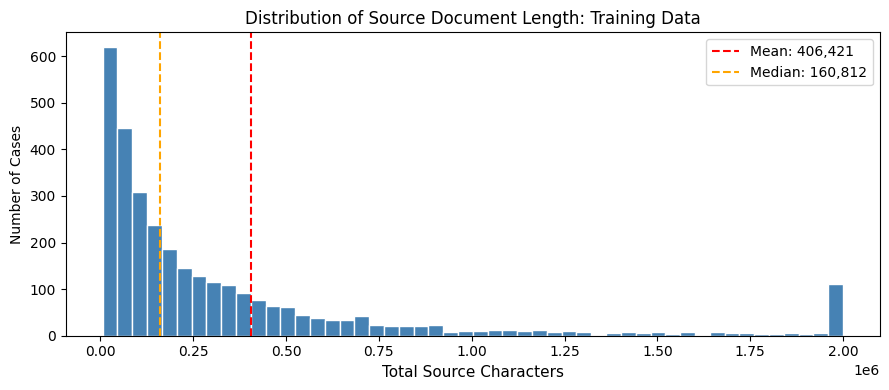

In [8]:
# Plot histogram of source lengths (capped at 2M)
fig, ax = plt.subplots(figsize=(9, 4))
clipped = np.clip(src_chars, 0, 2_000_000)
ax.hist(clipped, bins=50, color='steelblue', edgecolor='white')
ax.set_xlabel('Total Source Characters', fontsize=11)
ax.set_ylabel('Number of Cases')
ax.set_title('Distribution of Source Document Length: Training Data', fontsize=12)
ax.axvline(np.mean(src_chars), color='red', linestyle='--', label=f'Mean: {np.mean(src_chars):,.0f}')
ax.axvline(np.median(src_chars), color='orange', linestyle='--', label=f'Median: {np.median(src_chars):,.0f}')
ax.legend()
plt.tight_layout()
plt.show()

Source documents are highly right-skewed, with the majority of cases under 500,000 characters. A small handful exceed 2,000,000 characters.

## Build DataFrame

In [9]:
records = []

# Append summaries + case metadata
for split_name, split_data in dataset.items():
    for ex in split_data:
        meta = ex['case_metadata']
        records.append({
            'id': ex['id'],
            'split': split_name,
            'case_name': meta.get('case_name', ''),
            'case_type': meta.get('case_type', ''),
            'class_action_sought': meta.get('class_action_sought', ''),
            'filing_date': meta.get('filing_date', ''),
            'filing_year': meta.get('filing_year', ''),
            'prevailing_party': meta.get('prevailing_party', ''),
            'n_sources': len(ex['sources']),
            'full_text': ' '.join(ex['sources']),
            'total_chars': sum(len(s) for s in ex['sources']),
            'summary_long': ex.get('summary/long'),
            'summary_short': ex.get('summary/short'),
            'summary_tiny': ex.get('summary/tiny'),
        })

# Convert to DataFrame
df = pd.DataFrame(records)

# Print dimensions + column names
print(f'DataFrame shape: {df.shape}')
print(f'Columns: {list(df.columns)}')

DataFrame shape: (4539, 14)
Columns: ['id', 'split', 'case_name', 'case_type', 'class_action_sought', 'filing_date', 'filing_year', 'prevailing_party', 'n_sources', 'full_text', 'total_chars', 'summary_long', 'summary_short', 'summary_tiny']


In [10]:
# Print first five rows
df.head()

,id,split,case_name,case_type,class_action_sought,filing_date,filing_year,prevailing_party,n_sources,full_text,total_chars,summary_long,summary_short,summary_tiny
0,EE-AL-0045,train,"EEOC v. House of Philadelphia Center, Inc.",Equal Employment,No,2005-09-15,2005,Plaintiff,4,Case 1:05-cv-00530-D Document 1-1 Filed 09/19/...,32168,"On September 15, 2005, the Equal Employment Op...",Equal Employment Opportunity Commission brough...,NaN
1,PB-NJ-0003,train,Disability Rights New Jersey v. Velez,Public Benefits / Government Services,No,2005-04-05,2005,Plaintiff,4,Case 3:05-cv-01784-SRC-JJH Document 2 Filed 05...,152718,NOTE: This is one of three identically named ...,The case was brought by a non-profit organizat...,NaN
2,EE-FL-0136,train,United States v. Palm Beach County,Equal Employment,No,2007-08-09,2007,Mixed,3,Case 9:07-cv-80713-KAM Document 1 Entered on F...,41708,"On August 9, 2007, the United States Departmen...",NaN,NaN
3,EE-CA-0305,train,Wynne v. McCormick & Schmick's Seafood Restara...,Equal Employment,Yes,2006-05-11,2006,Plaintiff,13,2006 WL 1787244\n2006 WL 1787244 (N.D.Cal.) (T...,367008,"On May 11, 2006, African-American employees of...",This case was brought by African American empl...,NaN
4,NH-NJ-0002,train,"U.S. v. Mercer County, New Jersey",Nursing Home Conditions,No,2005-02-18,2005,Plaintiff,6,IN THE UNITED STATES DISTRICT COURT FOR THE DI...,105796,Pursuant to the Civil Rights of Institutionali...,Pursuant to the Civil Rights of Institutionali...,NaN


In [11]:
# Print data types
print(df.dtypes)

id                       str
split                    str
case_name                str
case_type                str
class_action_sought      str
filing_date              str
filing_year              str
prevailing_party         str
n_sources              int64
full_text                str
total_chars            int64
summary_long             str
summary_short            str
summary_tiny             str
dtype: object


In [12]:
# Count missing summaries by split
for split in ['train', 'validation', 'test']:
    sub = df[df['split'] == split]

    for col in ['summary_long', 'summary_short', 'summary_tiny']:
        missing = sub[col].isna().sum()
        print(f'{split} {col}: {missing} missing / {len(sub)} total ({missing/len(sub)*100:.1f}%)')

train summary_long: 0 missing / 3177 total (0.0%)
train summary_short: 967 missing / 3177 total (30.4%)
train summary_tiny: 2047 missing / 3177 total (64.4%)
validation summary_long: 0 missing / 454 total (0.0%)
validation summary_short: 142 missing / 454 total (31.3%)
validation summary_tiny: 293 missing / 454 total (64.5%)
test summary_long: 0 missing / 908 total (0.0%)
test summary_short: 292 missing / 908 total (32.2%)
test summary_tiny: 596 missing / 908 total (65.6%)


In [13]:
# Count case types by split
pivot = df.groupby(['split', 'case_type']).size().unstack(fill_value=0)
display(pivot.T.sort_values('train', ascending=False).head(10))

split,test,train,validation
case_type,,,
Equal Employment,325,1099,155
Immigration and/or the Border,96,367,60
Prison Conditions,81,313,30
Jail Conditions,58,223,22
Public Benefits / Government Services,52,204,32
Policing,36,143,22
Speech and Religious Freedom,26,134,13
Criminal Justice (Other),44,120,20
National Security,30,94,13


In [14]:
# Count class action sought by split
display(df.groupby(['split', 'class_action_sought']).size().unstack(fill_value=0))

class_action_sought,No,Unknown,Yes
split,,,
test,619,0,289
train,2109,2,1066
validation,298,1,155


## Clean Cases

In [15]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Pre-compile regex patterns for speed
re_url = re.compile(r'https?://\S+|www\.\S+')
re_cite = re.compile(r'\b\d+\s+(?:U\.S\.|F\.3d|F\.2d|F\.Supp\.?\d*|S\.Ct\.|L\.Ed\.2d)\s+\d+\b')
re_fn = re.compile(r'\[\d+\]')
re_docket = re.compile(r'Case\s+\d+:\d+-[a-z]+-\d+[^\n]{0,120}')
re_space = re.compile(r'\s+')

# Remove excess notation
def clean_text(text):
    if not text:
        return ''
    
    text = text.replace('\x0c', ' ')
    text = re_url.sub('', text)
    text = re_cite.sub('', text)
    text = re_fn.sub('', text)
    text = re_docket.sub('', text)
    text = re_space.sub(' ', text).strip()

    return text

# Tokenize, lemmatize, and remove stopwords
def normalize_text(text):
    text = clean_text(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))

    tokens = word_tokenize(text)
    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t.isalpha() and t not in stop_words and len(t) > 2
    ]

    return ' '.join(tokens)

In [26]:
# Clean full text
df['cleaned_text'] = df['full_text'].progress_apply(clean_text)

# Calculate ratio of characters removed
df['cleaned_chars'] = df['cleaned_text'].str.len()
df['chars_removed_pct'] = ((df['total_chars'] - df['cleaned_chars'])
                           / df['total_chars'].replace(0, 1) * 100).round(1)

# Print cleaning summary
print(df[['total_chars', 'cleaned_chars', 'chars_removed_pct']].describe().round(1))

100%|██████████| 4539/4539 [07:32<00:00, 10.03it/s]


       total_chars  cleaned_chars  chars_removed_pct
count       4539.0         4539.0             4539.0
mean      399409.3       386043.9                3.1
std       951243.6       918932.2                1.8
min         6052.0         5744.0                0.2
25%        58427.0        56720.5                1.8
50%       158734.0       153848.0                3.0
75%       399350.0       387192.0                4.2
max     23501994.0     22402099.0               25.0


In [32]:
# Normalize full text
df['normalized_text'] = df['full_text'].progress_apply(normalize_text)

  0%|          | 0/4539 [00:00<?, ?it/s]

100%|██████████| 4539/4539 [1:11:09<00:00,  1.06it/s]  


In [33]:
# Show before + after for a single case
idx = df[df['summary_tiny'].notna()].index[0]
raw = df.loc[idx, 'full_text'][:600]
cleaned = df.loc[idx, 'cleaned_text'][:600]
normed = df.loc[idx, 'normalized_text'][:600]

# Print first 600 characters of the original text
print('Original:')
print(f'{raw}\n')

# Print first 600 characters of the trimmed text
print('After light cleaning:')
print(f'{cleaned}\n')

# Print first 600 characters of the fully normalized text
print('After full normalization:')
print(f'{normed}\n')

Original:
Case 3:13-cv-24068 Document 8 Filed 10/01/13 Page 1 of 30 PageID #: 16

UNITED STATES DISTRICT COURT FOR THE SOUTHERN DISTRICT OF WEST VIRGINIA Huntington Division

CASIE JO MCGEE and SARAH ELIZABETH ADKINS; JUSTIN MURDOCK and WILLIAM GLAVARIS; and NANCY ELIZABETH MICHAEL and JANE LOUISE FENTON, individually and as next friends of A.S.M., a minor child;

Plaint[f{s,
v.
KAREN S. COLE, in her official capacity as CABELL COUNTY CLERK; and VERA J. MCCORMICK, in her official capacity as KANAWHA COlJNTY CLERK;

Civil

Action

No.

3:13-cv-24068
----

Defendants.

COMPLAINT FOR DECLARATORY AND INJUNC

After light cleaning:
UNITED STATES DISTRICT COURT FOR THE SOUTHERN DISTRICT OF WEST VIRGINIA Huntington Division CASIE JO MCGEE and SARAH ELIZABETH ADKINS; JUSTIN MURDOCK and WILLIAM GLAVARIS; and NANCY ELIZABETH MICHAEL and JANE LOUISE FENTON, individually and as next friends of A.S.M., a minor child; Plaint[f{s, v. KAREN S. COLE, in her official capacity as CABELL COUNTY CLERK; and 

In [34]:
# Save DataFrame to a pickle file
df.to_pickle("case_data.pkl")